## YouTube Chatbot System
We are building a RAG-based YouTube chatbot that extracts video transcripts, augments them with the user's prompt into a final context, and sends it to the LLM for a response within a pipeline.

In [44]:
import os
os.environ["OPENAI_API_KEY"] = "sk-XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX"

In [7]:
# Install Libraries
%pip install -q youtube-transcript-api langchain-community langchain-openai faiss-cpu tiktoken python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Import Libraries

# this library is used to extract the transcript of a YouTube video
from youtube_transcript_api import YouTubeTranscriptApi, TranscriptsDisabled

# this library is used to split the transcript into smaller chunks
from langchain_text_splitters import RecursiveCharacterTextSplitter

# this library is used to create embeddings for the transcript chunks
from langchain_openai import OpenAIEmbeddings                     # chatgpt embeddings model
from langchain_community.embeddings import HuggingFaceEmbeddings  # free embedding model

# this library is used to load to open-source LLM model hosted on HuggingFace
from langchain_openai import ChatOpenAI # chatgpt model
from langchain_huggingface import HuggingFaceEndpoint # huggingface model
from langchain_google_genai import ChatGoogleGenerativeAI # google ai studio model

# this library is used to create a vector store for the transcript chunks
from langchain_community.vectorstores import FAISS

# this library is used to create a prompt template for the LLM
from langchain_core.prompts import PromptTemplate

### Step 1a - Indexing (Document Injestion)
In which we extract the transcript text from video

In [5]:
video_id = "Gfr50f6ZBvo" #only the ID, not full URL
try:
    # if you dont care which language, this returns the "best" one
    # it extract/fetch transcript in timestamps based thats why we need to join them to make single paragraph transcript
    api = YouTubeTranscriptApi()
    transcript_list = api.fetch(video_id, languages=["en"])

    # Flatten it to plain text
    transcript = " ".join(chunk.text for chunk in transcript_list)
    print(transcript)

except TranscriptsDisabled:
    print("No captions available for this video")

the following is a conversation with demus hasabis ceo and co-founder of deepmind a company that has published and builds some of the most incredible artificial intelligence systems in the history of computing including alfred zero that learned all by itself to play the game of gold better than any human in the world and alpha fold two that solved protein folding both tasks considered nearly impossible for a very long time demus is widely considered to be one of the most brilliant and impactful humans in the history of artificial intelligence and science and engineering in general this was truly an honor and a pleasure for me to finally sit down with him for this conversation and i'm sure we will talk many times again in the future this is the lex friedman podcast to support it please check out our sponsors in the description and now dear friends here's demis hassabis let's start with a bit of a personal question am i an ai program you wrote to interview people until i get good enough 

### Step 1b - Indexing (Text Splitting)
In which we split the transcript into chunks

In [6]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.create_documents([transcript])

# No. of chunks
len(chunks)

168

### Step 1c & 1d - Indexing (Embedding Generation and Storing in Vector Store)
In which we generate embeddings for the text chunks and store/indexing them into the vector-store.

In [ ]:
%pip install sentence-transformers

In [7]:
# through embedding it create vector id for every text chunks and we can access chunk through that id
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

# store locally the embeddings in a vector store for easy retrieval
vector_store = FAISS.from_documents(chunks, embeddings)

C:\Users\iqrak\AppData\Local\Temp\ipykernel_26400\2900921569.py:2: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
C:\Users\iqrak\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5832.50it/s]


In [8]:
# vector id of every chunks
vector_store.index_to_docstore_id

{0: 'ac52cb12-2bb4-4712-9ca3-f3f8e0a836d5',
 1: '118dddb9-f2c5-48d3-8028-e2c72c8043ed',
 2: 'e56f68ab-1ad4-4f86-880f-43fdc64d790d',
 3: 'd6cae138-e3d5-4f3f-8813-cc7c35736b10',
 4: '2ecd6bc1-2b15-4e4a-b91a-a4d1f045f86e',
 5: '1274da17-9acb-44b4-8bda-83bf9e3a7664',
 6: '4dc6199e-64e2-4865-a60d-92d4b01bb33d',
 7: '26cc9112-ffec-4fbc-ac3e-cbd81eb9d83b',
 8: 'b2f952e4-dc2a-423f-b8ee-121188c434d6',
 9: '4b7ea519-d6fa-497e-a816-b450e5fe1d54',
 10: '4f486464-0647-4393-9b31-bf48f188e4ad',
 11: '18d8ea4f-4e01-4c1f-a066-ef3a8382e02e',
 12: '82853e95-6efe-4eff-aa2d-9cffefafc7f9',
 13: '1a78c66e-d36f-4b08-b263-08ad97369fb1',
 14: 'eb2c7d9c-8ef9-43ce-9167-ae2756d6cd3a',
 15: '2420ebde-b892-4f00-a4a5-32f979ae214a',
 16: '36c50da2-0098-4701-8f27-093aa8a6987e',
 17: 'ff527ccc-14c7-4a11-98e6-d4e826a6bcec',
 18: '316f25bb-9b4e-4cb1-9157-7a1ea34a5a81',
 19: '712a0428-5a81-4116-a8bc-61f7068a58ea',
 20: '4bee61d3-9548-41ca-80c4-7dcccdc79309',
 21: 'e8cf4123-d206-45b5-a271-e8196c16604a',
 22: 'a97e3275-ac0c-

In [9]:
# to check any particular chunk by their veector id
vector_store.get_by_ids(['7c472ac3-9ad0-4079-a3d2-ae08c9ccd13f'])

[]

## Step 2 - Retrieval
it used to retrieve text chunks which is relevant to input question

In [10]:
# it search type is similarity and search kwargs is return no. of relevant text chunks
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [11]:
retriever

VectorStoreRetriever(tags=['FAISS', 'HuggingFaceEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x0000025420898D70>, search_kwargs={'k': 4})

In [12]:
retriever.invoke('What is deepmind')

[Document(id='942ac312-1c52-4702-a820-bf1c3e859a87', metadata={}, page_content="and how it works this is tough to uh ask you this question because you probably will say it's everything but let's let's try let's try to think to this because you're in a very interesting position where deepmind is the place of some of the most uh brilliant ideas in the history of ai but it's also a place of brilliant engineering so how much of solving intelligence this big goal for deepmind how much of it is science how much is engineering so how much is the algorithms how much is the data how much is the hardware compute infrastructure how much is it the software computer infrastructure yeah um what else is there how much is the human infrastructure and like just the humans interact in certain kinds of ways in all the space of all those ideas how much does maybe like philosophy how much what's the key if um uh if if you were to sort of look back like if we go forward 200 years look back what was the key 

## Step 3 - Augmentation
it augment retrieve chunks context with query to build final prompt which is then sent to the LLM

In [13]:
#Here, we create a prompt template that merges the context with the user query to build the final prompt, which is then sent to the LLM for a response
prompt = PromptTemplate(
    template="""
     You are a helpful assistant,
     Answer ONLY from the provided transcript context,
     If the context is insufficient, just say you don't know.

     {context}
     Questions: {question}
     """,
     input_variables= ['context', 'question']
)

In [14]:
# Here, we pass the user query to the retriever to fetch relevant context from the vector store
question = "is the topic of alien discussed in this video? if yes then what was discussed"
retriever_docs = retriever.invoke(question)

In [15]:
retriever_docs

[Document(id='b5a6ed17-5232-45ba-a41f-4eb10d54232b', metadata={}, page_content="space age we should have heard a cacophony of voices we should have joined that cacophony of voices and what we did we opened our ears and we heard nothing and many people who argue that there are aliens would say well we haven't really done exhaustive search yet and maybe we're looking in the wrong bands and and we've got the wrong devices and we wouldn't notice what an alien form was like to be so different to what we're used to but you know i'm not i don't really buy that that it shouldn't be as difficult as that like we i think we've searched enough there should be if it were everywhere if it was it should be everywhere we should see dyson's fears being put up sun's blinking in and out you know there should be a lot of evidence for those things and then there are other people argue well the sort of safari view of like well we're a primitive species still because we're not space faring yet and and and we

In [16]:
# Combine the page content of all retrieved documents into a single context string for the prompt
context_text = "\n\n".join(doc.page_content for doc in retriever_docs)
context_text

"space age we should have heard a cacophony of voices we should have joined that cacophony of voices and what we did we opened our ears and we heard nothing and many people who argue that there are aliens would say well we haven't really done exhaustive search yet and maybe we're looking in the wrong bands and and we've got the wrong devices and we wouldn't notice what an alien form was like to be so different to what we're used to but you know i'm not i don't really buy that that it shouldn't be as difficult as that like we i think we've searched enough there should be if it were everywhere if it was it should be everywhere we should see dyson's fears being put up sun's blinking in and out you know there should be a lot of evidence for those things and then there are other people argue well the sort of safari view of like well we're a primitive species still because we're not space faring yet and and and we're you know there's some kind of globe like universal rule not to interfere\n\

In [17]:
# Format the prompt template by injecting the retrieved context and user question to create the final LLM input
final_prompt = prompt.invoke({"context": context_text, "question": question})

## Step 4 - Generation
Here we generate response on bases of final prompt through LLM models


In [ ]:
%pip install langchain-huggingface

In [ ]:
%pip install -qU langchain-google-genai

In [41]:
# llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.2)



# Apna Free Hugging Face Token yahan rakhein
# os.environ["HUGGINGFACEHUB_API_TOKEN"] = "hf_your_free_token_here"

# Free open-source huggingface model load karein
# repo_id = "meta-llama/Meta-Llama-3-8B-Instruct"

# Free HuggingFace model load karein
# llm = HuggingFaceEndpoint(
#     repo_id=repo_id,
#     temperature=0.2,
#     max_new_tokens=512
# )



# Apni Gemini API Key yahan rakhein
os.environ["GOOGLE_API_KEY"] = "google_api_key_here"

# Free Gemini model load karein
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.2
)

In [ ]:
# Generate Response through LLM
answer = llm.invoke(final_prompt)
print(answer.content)

## Building a Chain
Here, we automate this pipeline so that we dont need to manually invoke retriever, prompt, LLM model, etc

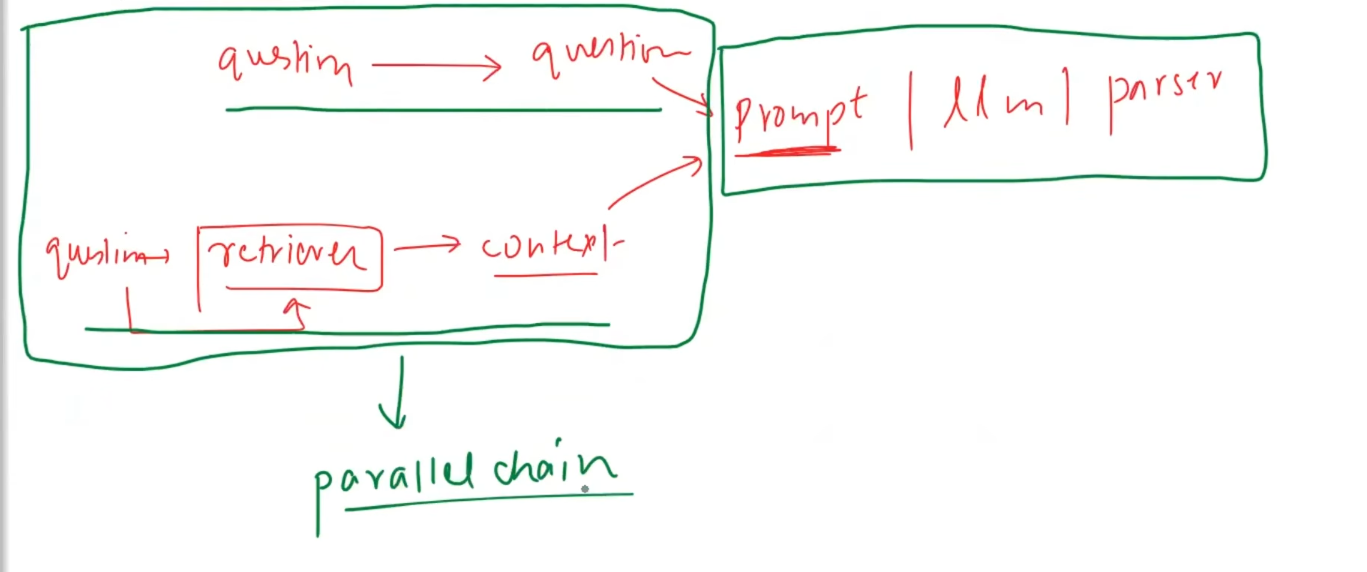

In [29]:
# this library is used to run multiple runnables in parallel, pass through inputs, and create lambda functions for custom processing
from langchain_core.runnables import RunnableParallel, RunnablePassthrough, RunnableLambda

# this library is used to parse the output of the LLM into a string format
from langchain_core.output_parsers import StrOutputParser

In [30]:
# here we define a function that takes the retrieved documents and formats them into a single string of context text, which can then be used in the prompt for the LLM.
def format_docs(retriever_docs):
    context_text = "\n\n".join(doc.page_content for doc in retriever_docs)
    return context_text

In [ ]:
# here we create a parallel chain that runs the retriever and formats the retrieved documents into a single string of context text, while also passing through the user question to the LLM.
parallel_chain = RunnableParallel({
    # chain 1 - here we run the retriever and format the retrieved documents into a single string of context text
    'context': retriever | RunnableLambda(format_docs),
    # chain 2 - here we pass through the user question to the LLM
    'question': RunnablePassthrough()
})

In [37]:
# we can now invoke the parallel chain with a user question
parallel_chain.invoke('who is Demis')

{'context': "to get world peace because there's also other corrupting things like wanting power over people and this kind of stuff which is not necessarily satisfied by by just abundance but i think it will help um and i think uh but i think ultimately ai is not going to be run by any one person or one organization i think it should belong to the world belong to humanity um and i think maybe many there'll be many ways this will happen and ultimately um everybody should have a say in that do you have advice for uh young people in high school and college maybe um if they're interested in ai or interested in having a big impact on the world what they should do to have a career they can be proud of her to have a life they can be proud of i love giving talks to the next generation what i say to them is actually two things i i think the most important things to learn about and to find out about when you're when you're young is what are your true passions is first of all there's two things on

In [38]:
# here we create an output parser that will convert the LLM's output into a string format
parser = StrOutputParser()

In [39]:
# here we define the main chain that combines the parallel chain, prompt template, LLM, and output parser into a single runnable that can be invoked with a user question to generate a response.
main_chain = parallel_chain | prompt | llm | parser

In [35]:
# here we invoke the main chain with a user question to generate a response from the LLM based on the retrieved context from the vector store.
main_chain.invoke('Can you summarize the video')

"Based on the provided transcript, the conversation covers the following topics:\n\n* **Explanations of Physics and Mysteries:** A discussion on how an advanced intelligence might explain the universe, suggesting it would offer simpler, deeper explanations of fundamental physics beyond the standard model, shedding light on mysteries like consciousness, life, and gravity.\n* **Simplicity as a Sign of Intelligence:** Referencing Richard Feynman, the speakers note that true understanding and intelligence are demonstrated by the ability to explain complex ideas simply. They also mention that humans are already in a symbiotic relationship with their computing devices.\n* **History of Chess Computing:** A reflection on early chess programming, including Claude Shannon's 1949 paper and Alan Turing manually executing his chess program on pencil and paper. The speaker recalls the Deep Blue match and being more impressed by Garry Kasparov’s versatile human mind than by the machine's brute calcul

## Improvements in RAG based System

### 1. UI based enhancements
make UI for RAG system or make chrome-plugin(extension type UI system)

### 2. Evaluation
these are methods to check our RAG system response are correct or not for improvement

a. Ragas - it evaluate in different metrics like ->

- faithfulness - it measure the answer grounded/related with the retrieved context
- answer_relevancy - it measure the answer is relevant to the user question
- context_precision - it measure how much of the retrieved context is actually useful
- context_recall - it measure that we retrieved all necessary information

b. LangSmith - it tracing the response in each step to check our pipeline is working fine or not

### 3. Indexing
a. Document Ingestion - fix errors(language, wording, etc) after fetching transcript from video because those transcript are auto-generated

b. Text Splitting - we can use semantic chunkers for better splitting

c. Vector Store - we can use cloud based vector store like Pinecone

### 4. Retrieval
#### a. Pre-Retrieval
- Query rewriting using LLM - improve user query using LLMs
- Multi-query generation - generate multiple user query, if original user query is weak
- Domain aware routing - based on the user query we route domain specific retriever

#### b. During Retrieval
- MMR
- Hybrid Retrieval
- Reranking - Instead similarity retriever we can use reranking based retriever so that we can place most relevant retriever text chunks on top

#### c. Post-Retrieval
- Contextual Compression

### 5. Augmentation
a. Prompt Templating

b. Answer grounding

c. Contex window optimization - here we trim the context so that only useful part stay in contex and we dont reach context window limit

### 6. Generation
a. Answer with Citation - it gives answer and tell answer is from which part of context 

b. Guard railing - it used so that LLMs not give wrong information to user

### 7. System Design
a. Multimodel - our multi model RAG based system can process text, image, etc

b. Agentic - our RAG system work with AI agents

c. Memory based - old context answer current user query